<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/Deep_ONet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computing ODE operator with DeepONets

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# Set the seed before generating data or initializing a network
np.random.seed(42)
torch.manual_seed(42)

## ODE definition


**ODE and Euler Method**

We consider the following ordinary differential equation (ODE):
$$
  \frac{dy}{dt} = q(t) - y(t),
$$
where $ q(t) $ is a given function of time, and $ y(t) $ is the unknown function we seek to solve. The goal is to find $ y(t) $ for $ t \in [0, T] $, given the initial condition:

$$
  y(0) = y_0.
$$

Reminder: when $q(t) = t$, we have an explicit solution. But in general we do not, so we will rely on a numerical method to compute the true (approximate) solution.

**Euler's Method**

Euler's method is a simple numerical approach to solve first-order ODEs. We discretize the time interval $[0, T]$ into $ N_t $ equally spaced time points with a time step $ \Delta t $ given by:

$$
  \Delta t = \frac{T}{N_t - 1}.
$$

At each time step $ t_n $, the value of $ y(t) $ is updated using the formula:

$$
  y_{n+1} = y_n + \Delta t \cdot \left( q(t_n) - y_n \right),
$$
for $ n = 0, 1, 2, \dots, N_t - 2 $.

Here:
- $ y_n $ is the numerical approximation of $ y(t_n) $,
- $ t_n $ is the $ n $-th time point: $ t_n = n \Delta t $,
- $ q(t_n) $ is the value of the function $ q(t) $ at time $ t_n $.


## Computing a reference solution (Euler method)

In [2]:
def euler_ode_solver(y0, T, Nt, q):
    """
    Solves the ODE dy/dt = q(t) - y(t) using Euler's method.

    Args:
        y0 (float): Initial condition y(0).
        T (float): Time horizon.
        Nt (int): Number of time points.
        q (array-like): Array of q values at the time points.

    Returns:
        y (np.ndarray): Approximate solution values at the time points.
    """
    # Time step
    dt = T / (Nt - 1)

    # Initialize arrays for time and solution
    t = np.linspace(0, T, Nt)
    y = np.zeros(Nt)

    # Set initial condition
    y[0] = y0

    # Euler method
    for n in range(1, Nt):
        y[n] = y[n-1] + dt * (q[n-1] - y[n-1])  # Euler step

    return y

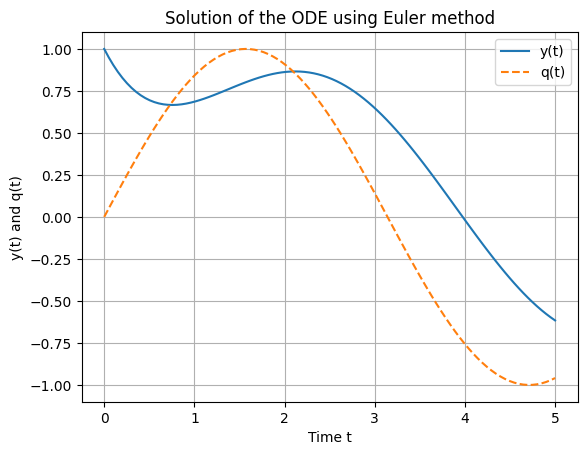

In [3]:
# Example usage
T = 5.0        # Time horizon
Nt = 100       # Number of time points
y0 = 1.0       # Initial condition
t = np.linspace(0, T, Nt)

# Example q(t) = sin(t)
q = np.sin(t)

# Solve the ODE
y = euler_ode_solver(y0, T, Nt, q)

# Plot the solution
plt.plot(t, y, label='y(t)')
plt.plot(t, q, label='q(t)', linestyle='--')
plt.xlabel('Time t')
plt.ylabel('y(t) and q(t)')
plt.legend()
plt.title('Solution of the ODE using Euler method')
plt.grid(True)
plt.show()

## Sanity check: Euler's method

Before using Euler solutions as training labels, we check the solver on a problem with a known solution. For $q(t)=t$ and initial value $y(0)=y_0$, the exact solution is

$$
y(t)=t-1+(y_0+1)e^{-t}.
$$

We compute the maximum error on the time grid for several step sizes.
Euler's method is first order, so we expect the error to decrease
approximately by a factor of two when the step size is halved.

In [4]:
# Check Euler's method against the exact solution for q(t) = t
check_T = 1.0
check_y0 = 1.0

for check_Nt in [26, 51, 101]:
    check_t = np.linspace(0, check_T, check_Nt)
    check_q = check_t
    check_dt = check_T / (check_Nt - 1)

    check_y_euler = euler_ode_solver(
        check_y0, check_T, check_Nt, check_q
    )
    check_y_exact = (
        check_t - 1 + (check_y0 + 1) * np.exp(-check_t)
    )

    max_error = np.max(np.abs(check_y_euler - check_y_exact))
    print(f"dt = {check_dt:.3f}, maximum error = {max_error:.6f}")

dt = 0.040, maximum error = 0.014965
dt = 0.020, maximum error = 0.007420
dt = 0.010, maximum error = 0.003694


## Generating random functions on [0,T]

A Gaussian random field (GRF) is a collection of random variables indexed by a spatial domain, where every finite subset of points has a multivariate Gaussian distribution. The covariance structure of these random variables is defined by the kernel $k(x, x')$. The Matérn kernel or squared exponential kernel (also called the Radial Basis Function or RBF kernel) is often used to define the spatial correlation between different points in a GRF.

For the given kernel
$$
k(x, x') = \exp\left(-\frac{\|x - x'\|^2}{2 \ell^2}\right),
$$
the steps to sample a GRF are:

1. **Define a set of points**: Choose a set of spatial points $x_1, x_2, \ldots, x_N$ where you want to sample the function values.

2. **Construct the covariance matrix**: For these points, build an $N \times N$ covariance matrix $K$, where
$$
K_{ij} = k(x_i, x_j) = \exp\left(-\frac{\|x_i - x_j\|^2}{2 \ell^2}\right).
$$
This matrix defines the covariance between the values of the GRF at the sampled points.

3. **Sample from the multivariate Gaussian**: Once the covariance matrix is constructed, you can sample function values at the points by sampling from a multivariate normal distribution with mean zero and covariance matrix $K$. This will give you one realization of the GRF.


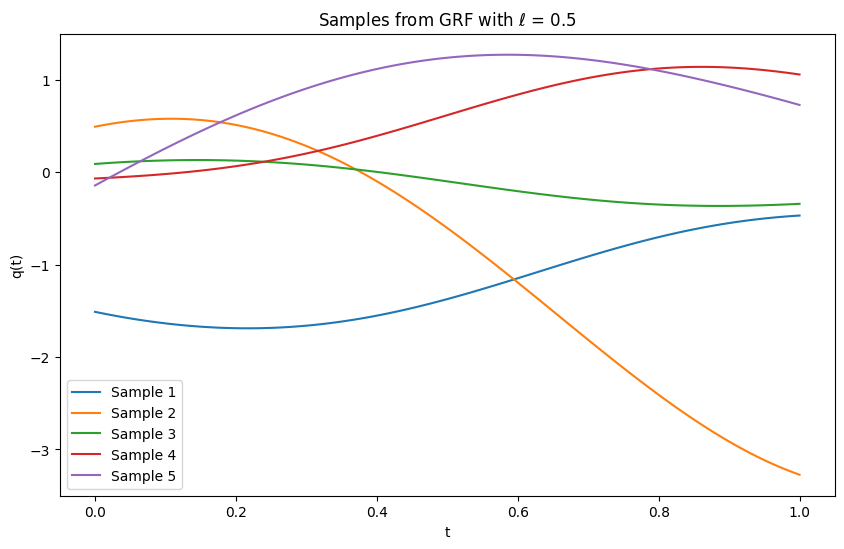

In [7]:
# Define the squared exponential (RBF) kernel
def rbf_kernel(x1, x2, ell):
    """Squared exponential kernel."""
    return np.exp(-np.sum((x1 - x2)**2) / (2 * ell**2))

# Generate covariance matrix using RBF kernel
def covariance_matrix(x, ell):
    """Generate covariance matrix for inputs x with length scale ell."""
    N = len(x)
    K = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            K[i, j] = np.exp(-np.sum((x[i]-x[j])**2)/(2*ell**2))
    return K

# Sample from Gaussian Random Field
def sample_grf(x, ell, num_samples=1):
    """Sample from a Gaussian random field at locations x with length scale ell."""
    # Generate the covariance matrix for the spatial points
    K = covariance_matrix(x, ell)

    # Sample from multivariate normal with mean 0 and covariance matrix K
    mean = np.zeros(len(x))
    samples = np.random.multivariate_normal(mean,K,size=num_samples) #Use np.random.multivariate_normal
    return samples

# Parameters for the ODE operator-learning example
T = 1.0     # Time domain [0, T]
Nt = 100    # Number of time points
y0 = 1.0    # Initial condition
ell = 0.5   # Length scale of the input functions

# Generate time points
t_grid = np.linspace(0, T, Nt).reshape(-1, 1)

# Sample from the GRF
num_samples = 5  # Number of functions to sample
samples = sample_grf(t_grid, ell, num_samples=num_samples)

# Plot the sampled functions
plt.figure(figsize=(10, 6))
for i in range(num_samples):
    plt.plot(t_grid[:, 0], samples[i], label=f'Sample {i+1}')
plt.title(f'Samples from GRF with $\\ell$ = {ell}')
plt.xlabel('t')
plt.ylabel('q(t)')
plt.legend()
plt.show()

Exercise:
- try small ell
- compare with samples having independent values at the grid points: use the identity matrix as the covariance matrix

## Generating samples of q

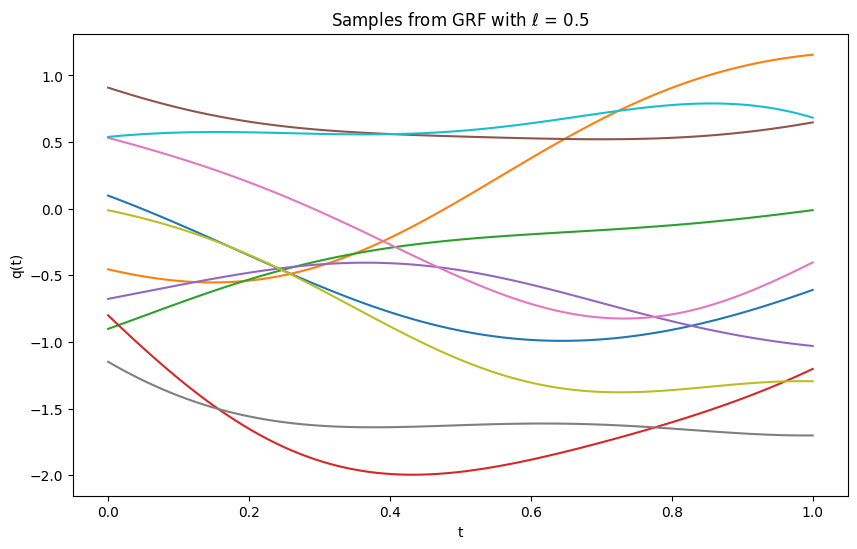

In [8]:
# Generate several GRF samples using one covariance matrix
def generate_grf_samples(num_samples, grid_points, ell=0.1):
    return sample_grf(grid_points, ell=ell, num_samples=num_samples)

# Define the grid points (x-domain) for each source term g
num_t_q = Nt # same number of points as in the Euler code for simplicity

num_q = 10 # Number of q for training

t_grid = np.linspace(0, T, num_t_q)  # time points
q_samples = generate_grf_samples(num_q, t_grid, ell=ell)  # samples of q

# Plot the sampled functions
plt.figure(figsize=(10, 6))
for q in q_samples:
    plt.plot(t_grid, q)
plt.title(f'Samples from GRF with $\\ell$ = {ell}')
plt.xlabel('t')
plt.ylabel('q(t)')
plt.show()

In [9]:
# Function to solve the ODE for each source term q
def solve_ode_for_q(q, y0, T, Nt):
    return euler_ode_solver(y0, T, Nt, q)

# Compute the Euler reference solution for each training input.
y_solutions = np.array([
    solve_ode_for_q(q, y0=y0, T=T, Nt=Nt)
    for q in q_samples
]) #Get reference solutions, List of ODE solutions

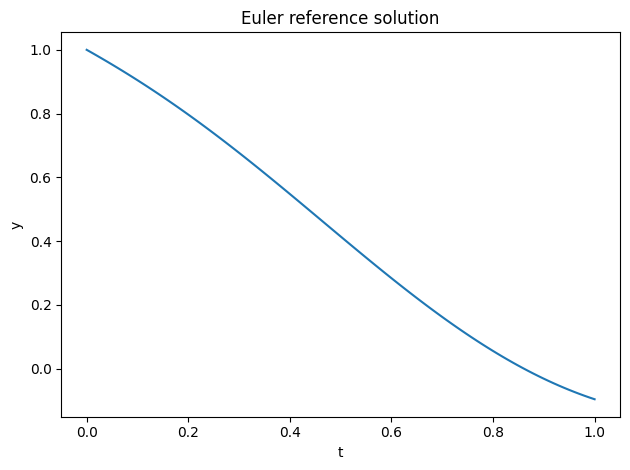

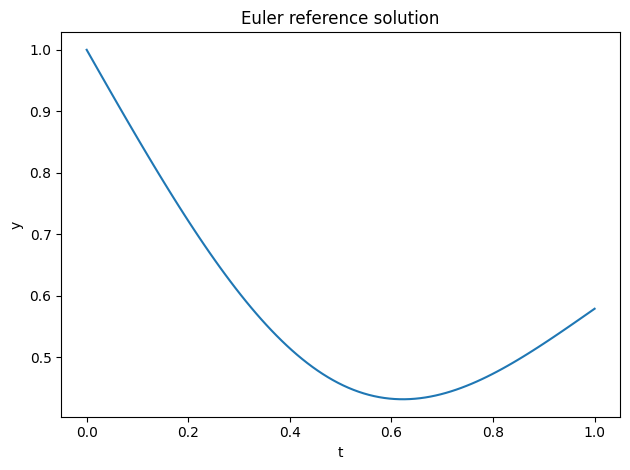

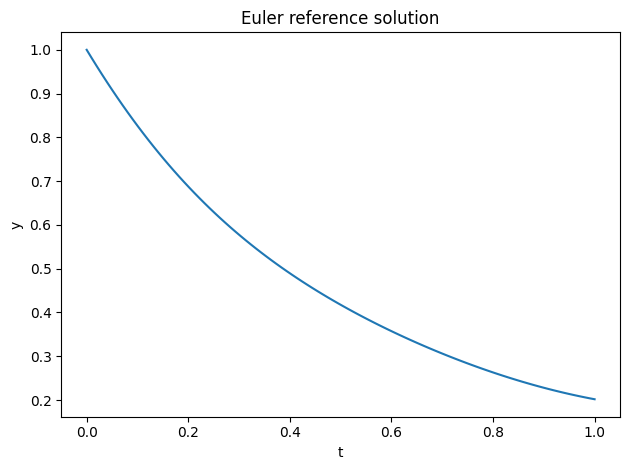

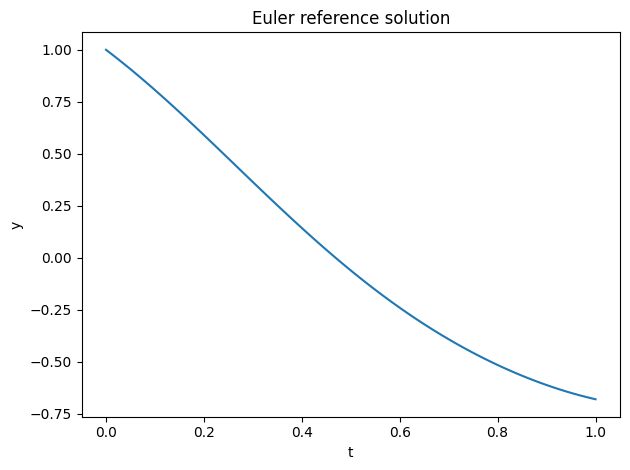

In [10]:
# Plot the reference solutions
grid_size_t = Nt

q_samples = torch.tensor(q_samples).clone().detach().float()
y_solutions = torch.tensor(y_solutions).clone().detach().float()

for i_q in range(min(q_samples.shape[0], 4)):
  # Choose one q function from the pre-generated dataset
  q = q_samples[i_q].unsqueeze(0)

  # Solve the reference solution using Euler for comparison
  y_ref = y_solutions[i_q].detach().numpy()  # The reference solution for the selected q

  # Plot reference solution using Euler method
  plt.plot(t_grid, y_ref)
  plt.title('Euler reference solution')
  plt.xlabel('t')
  plt.ylabel('y')

  plt.tight_layout()
  plt.show()

## DeepONet class

**DeepONet architecture**

For the ODE, we want to learn the solution operator

$$
\mathcal{G}: q \longmapsto y,
$$

where $y$ is the solution corresponding to the input function $q$.
The initial condition and the time interval are fixed.

A DeepONet approximates the value of this operator at a query time $t$:

$$
\widehat{\mathcal{G}}(q)(t)
=
\sum_{r=1}^{p}
b_r\bigl(q(s_1),\ldots,q(s_m)\bigr)\,\tau_r(t)
+\beta.
$$

- $s_1,\ldots,s_m$ are fixed **sensor locations** in time.
- The **branch network** takes the sensor values
  $(q(s_1),\ldots,q(s_m))$ as input and returns the coefficients
  $(b_1,\ldots,b_p)$.
- The **trunk network** takes the query time $t$ as input and returns
  $(\tau_1(t),\ldots,\tau_p(t))$.
- The predicted solution value is the dot product of these two outputs,
  plus a learned scalar bias $\beta$.

For a new input function $q$, we evaluate it at the same sensor
locations and pass those values to the branch network. We can then
evaluate the predicted solution at different query times by changing
the trunk input.

In [ ]:
# Define the DeepONet architecture
class DeepONet(nn.Module):
    def __init__(self, input_dim_sensor, input_dim_y,
                 hidden_dim=64, p_dim=20):
        super().__init__()

        # Input: values of the input function at fixed sensor locations
        self.branch_net = nn.Sequential( ) #TODO

        # Input: a query location, either t or (t, x)
        self.trunk_net = nn.Sequential(
            # TODO
        )

        # Scalar bias in the DeepONet output
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, sensor_values, query_points):
        branch_out = # TODO
        trunk_out = # TODO

        # Both outputs have p_dim components
        return # TODO

## Evaluation function

In [ ]:
def evaluate_mse(model, sensor_indices, inputs, solutions, query_points):
    """
    Compute MSE on a fixed set of query points.

    inputs:       [number of functions, number of input grid points]
    solutions:    [number of functions, number of query points]
    query_points: [number of query points, trunk input dimension]
    """
    model.eval()
    total_squared_error = 0.0
    total_values = 0

    with torch.no_grad():
        for input_values, reference_values in zip(inputs, solutions):
            sensor_values = input_values[sensor_indices].unsqueeze(0)
            sensor_values = sensor_values.repeat(len(query_points), 1)

            prediction = model(sensor_values, query_points).squeeze(-1)
            total_squared_error += torch.sum(
                (prediction - reference_values) ** 2
            ).item()
            total_values += reference_values.numel()

    model.train()
    return total_squared_error / total_values

## Computing operator with DeepONets

In [ ]:
# Training function
def train_ode_deeponet(
    deepONet, sensor_indices, q_samples, y_samples,
    q_val, y_val, query_points,
    n_epochs=1000, batch_size=32, lr=0.001, eval_every=100
    ):
    optimizer = torch.optim.Adam(deepONet.parameters(), lr=lr)
    n_samples = q_samples.shape[0]
    grid_size = q_samples.shape[1]  # Size of the time grid
    if batch_size > n_samples:
      batch_size = n_samples

    # Lists to store losses
    train_losses = []
    eval_epochs = []
    train_mses = []
    val_mses = []

    for epoch in range(n_epochs):
        epoch_loss = 0.0
        # Shuffle the dataset at the beginning of each epoch
        permutation = torch.randperm(n_samples)

        # Loop over mini-batches
        for i in range(0, n_samples, batch_size):
            # Get the mini-batch indices
            indices = permutation[i:i+batch_size]

            # Get the batch of source terms and their corresponding solutions
            q_batch = q_samples[indices]  # Shape: [batch_size, grid_size]
            y_batch = y_samples[indices]  # Shape: [batch_size, grid_size]

            # Initialize loss for this batch
            batch_loss = 0.0

            # Sample sensor points for each source term in the batch
            b_real = q_batch.shape[0]
            for j in range(b_real):
                # Compute sensor values
                sensor_values = # TODO  # Shape: [1, m_sensor]

                # Pick a random query point in time for the trunk network
                query_random_index = torch.randint(0, grid_size, (1,))
                input_random = query_points[query_random_index]

                # Get the reference solution value for the randomly chosen (t, x) point
                y_ref = # TODO

                # Predict the solution using DeepONet
                y_pred = # TODO

                # Compute the squared error for this prediction
                batch_loss += # TODO

            # Compute the average loss over the batch
            batch_loss /= b_real

            # Backpropagation
            optimizer.zero_grad()
            batch_loss.backward()
            optimizer.step()

            epoch_loss += batch_loss.item() * b_real

        # Average the minibatch losses over all training functions
        epoch_loss /= n_samples
        train_losses.append(epoch_loss)

        # Evaluation
        if (epoch + 1) % eval_every == 0 or epoch == n_epochs - 1:
            train_mse = evaluate_mse(
                deepONet, sensor_indices, q_samples, y_samples, query_points
            )
            val_mse = evaluate_mse(
                deepONet, sensor_indices, q_val, y_val, query_points
            )

            eval_epochs.append(epoch + 1)
            train_mses.append(train_mse)
            val_mses.append(val_mse)

        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {epoch_loss:.6e}")

    return train_losses, eval_epochs, train_mses, val_mses

In [ ]:
# Choose fixed sensor locations on the time grid
ode_m_sensor = 20
ode_sensor_indices = torch.randperm(Nt)[:ode_m_sensor]

# The branch input has one value per sensor; the trunk input is t
ode_model = DeepONet(input_dim_sensor=ode_m_sensor, input_dim_y=1)

# Training and validation settings
ode_epochs = 1000
ode_batch_size = 32
ode_learning_rate = 0.001
ode_eval_every = 100
num_q_val = 5

# Generate new input functions that are not used for training
q_val_np = generate_grf_samples(num_q_val, t_grid, ell=ell)
y_val_np = np.array([
    solve_ode_for_q(q, y0=y0, T=T, Nt=Nt)
    for q in q_val_np
])

q_val = torch.tensor(q_val_np, dtype=torch.float32)
y_val = torch.tensor(y_val_np, dtype=torch.float32)

# Evaluate both datasets at the same points on the time grid
ode_query_points = torch.tensor(t_grid, dtype=torch.float32).unsqueeze(1)

q_samples = q_samples.clone().detach().float()
y_solutions = y_solutions.clone().detach().float()

ode_train_losses, ode_eval_epochs, ode_train_mses, ode_val_mses = train_ode_deeponet(
    ode_model, ode_sensor_indices, q_samples, y_solutions,
    q_val, y_val, ode_query_points,
    n_epochs=ode_epochs,
    batch_size=ode_batch_size,
    lr=ode_learning_rate,
    eval_every=ode_eval_every,
)

Epoch 100/1000, Loss: 1.085893e-02
Epoch 200/1000, Loss: 4.806516e-03
Epoch 300/1000, Loss: 3.923631e-03
Epoch 400/1000, Loss: 4.844908e-03
Epoch 500/1000, Loss: 6.685679e-03
Epoch 600/1000, Loss: 2.150823e-03
Epoch 700/1000, Loss: 4.613057e-03
Epoch 800/1000, Loss: 7.700498e-04
Epoch 900/1000, Loss: 1.473898e-03
Epoch 1000/1000, Loss: 1.509650e-03


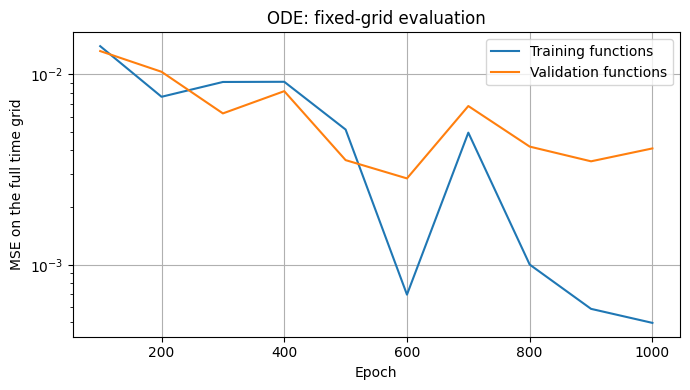

In [ ]:
# Plotting
plt.figure(figsize=(7, 4))
plt.semilogy(ode_eval_epochs, ode_train_mses, label="Training functions")
plt.semilogy(ode_eval_epochs, ode_val_mses, label="Validation functions")
plt.xlabel("Epoch")
plt.ylabel("MSE on the full time grid")
plt.title("ODE: fixed-grid evaluation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

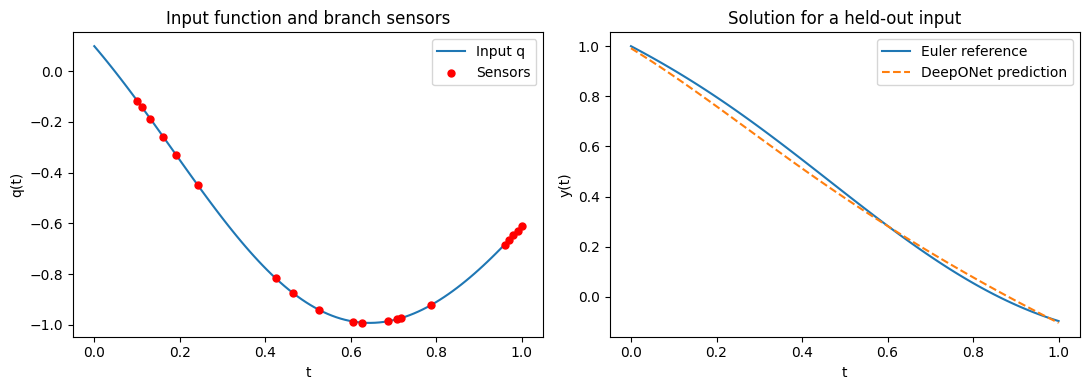

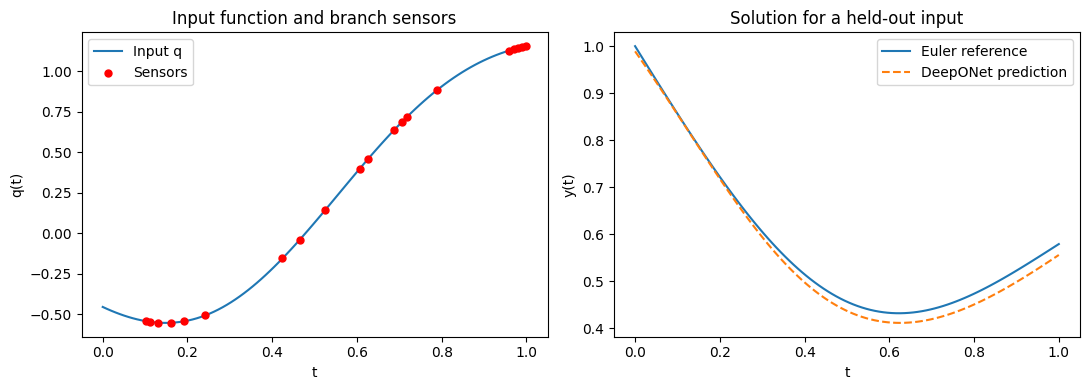

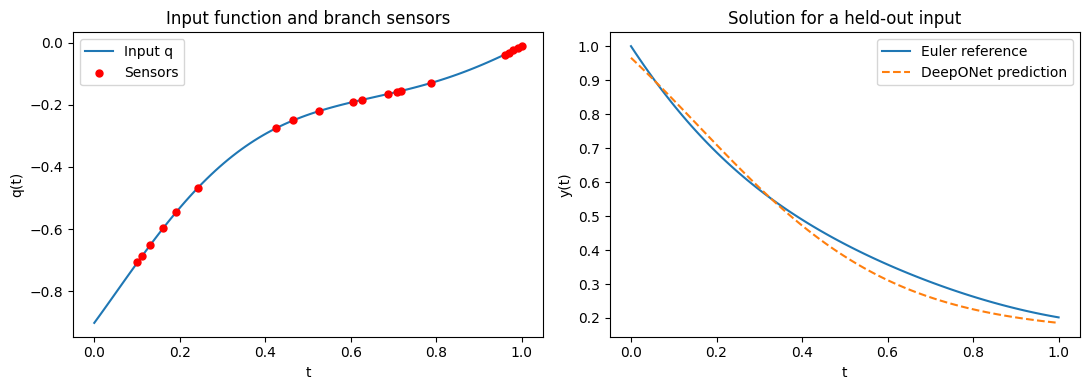

In [ ]:
# Plot a few held-out input functions and their predicted solutions.
ode_model.eval()
num_q_plot = min(3, len(q_val))

ode_plot_grid = ode_query_points.squeeze(1).numpy()

with torch.no_grad():
    for i_q in range(num_q_plot):
        q = q_val[i_q]
        sensor_values = q[ode_sensor_indices].unsqueeze(0)
        sensor_values = sensor_values.repeat(len(ode_query_points), 1)

        y_pred = ode_model(sensor_values, ode_query_points).squeeze(-1)
        y_ref = y_val[i_q]

        fig, axs = plt.subplots(1, 2, figsize=(11, 4))

        axs[0].plot(ode_plot_grid, q.numpy(), label="Input q")
        axs[0].scatter(
            ode_plot_grid[ode_sensor_indices.numpy()],
            q[ode_sensor_indices].numpy(),
            color="red", s=25, label="Sensors", zorder=3
        )
        axs[0].set_xlabel("t")
        axs[0].set_ylabel("q(t)")
        axs[0].set_title("Input function and branch sensors")
        axs[0].legend()

        axs[1].plot(ode_plot_grid, y_ref.numpy(), label="Euler reference")
        axs[1].plot(
            ode_plot_grid, y_pred.numpy(), "--", label="DeepONet prediction"
        )
        axs[1].set_xlabel("t")
        axs[1].set_ylabel("y(t)")
        axs[1].set_title("Solution for a held-out input")
        axs[1].legend()

        plt.tight_layout()
        plt.show()

## Exercises

- repeat with several seeds; plot mean +/- std err
- improve the results (get predictions closer to reference values)
- generate a separate test set of q functions and report the test error; keep the same sensor locations as during training
- try with different $\ell$ (length scale for GRF)
- try with other ODEs